# Telecom Customer Churn Analytics & Prediction
## Notebook -5 Model Evaluation

In this notebook, the trained machine learning models are evaluated using multiple classification metrics.

Instead of relying only on accuracy, we evaluate models using:

- Confusion Matrix
- Accuracy
- Precision
- Recall
- F1 Score
- Classification Report
- ROC Curve
- ROC-AUC Score

These metrics help determine which model is most suitable for predicting customer churn from both a machine learning and business perspective.

# Import Libraries

In [3]:
import pandas as pd
import numpy as np
import joblib

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Load Train and Test Data

In [5]:
train_df = pd.read_csv("../Data/processed/train_data.csv")

test_df = pd.read_csv("../Data/processed/test_data.csv")

In [6]:
print(train_df.shape)
print(test_df.shape)

(5634, 31)
(1409, 31)


In [7]:
X_train = train_df.drop("Churn", axis=1)
y_train = train_df["Churn"]

X_test = test_df.drop("Churn", axis=1)
y_test = test_df["Churn"]

### Load Saved Models

In [9]:
best_lr = joblib.load("../models/logistic_regression.pkl")

best_rf = joblib.load("../models/random_forest.pkl")

In [10]:
lr_pred = best_lr.predict(X_test)

rf_pred = best_rf.predict(X_test)

## Confusion Matrix

#### **Logistic Regression**

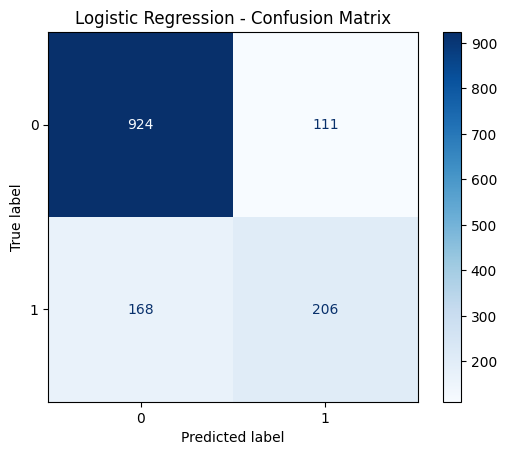

In [13]:
cm_lr=confusion_matrix(y_test,lr_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr)

disp.plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")

plt.show()

#### **Random Forest**

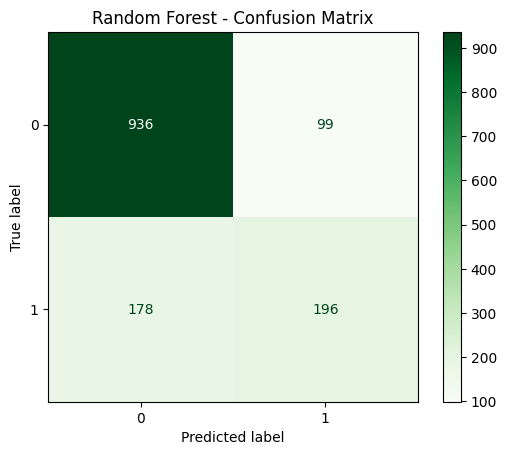

In [15]:
cm_rf = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)

disp.plot(cmap="Greens")

plt.title("Random Forest - Confusion Matrix")

plt.show()

## Accuracy

In [17]:
lr_accuracy = accuracy_score(y_test, lr_pred)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Logistic Regression Accuracy :", round(lr_accuracy,4))

print("Random Forest Accuracy :", round(rf_accuracy,4))

Logistic Regression Accuracy : 0.802
Random Forest Accuracy : 0.8034


### **📌 Key Takeaway**

Accuracy tells us how often the model is correct overall, but it does not tell us how well the model identifies churn customers.

**For a telecom company, finding customers who are likely to leave is the main objective. That's why, after understanding Accuracy, the next metrics—Precision, Recall, and F1 Score—become even more important. They focus specifically on the quality of churn predictions rather than just the total number of correct predictions.**

## Precision
**Out of all the customers we predicted would churn, how many actually churned?**

**High Precision means:**

- Fewer unnecessary retention offers
- Less marketing cost
- Better use of customer support resources

**Low Precision means:**

- Many loyal customers are incorrectly targeted
- Discounts and retention efforts are wasted

In [20]:
lr_precision = precision_score(y_test, lr_pred)

rf_precision = precision_score(y_test, rf_pred)

print("Logistic Regression Precision :", round(lr_precision,4))
print("Random Forest Precision :", round(rf_precision,4))

Logistic Regression Precision : 0.6498
Random Forest Precision : 0.6644


## Recall
**Out of all customers who actually churned, how many did we successfully detect?**

**High Recall means:**
- Very few churn customers are missed.
- More customers can receive retention offers.
- Lower revenue loss.

**Low Recall means:**
- Many customers quietly leave without any intervention.

In [22]:
lr_recall = recall_score(y_test, lr_pred)

rf_recall = recall_score(y_test, rf_pred)

print("Logistic Regression Recall :", round(lr_recall,4))
print("Random Forest Recall :", round(rf_recall,4))

Logistic Regression Recall : 0.5508
Random Forest Recall : 0.5241


## F1 Score

In [24]:
lr_f1 = f1_score(y_test, lr_pred)

rf_f1 = f1_score(y_test, rf_pred)

print("Logistic Regression F1 Score :", round(lr_f1,4))
print("Random Forest F1 Score :", round(rf_f1,4))

Logistic Regression F1 Score : 0.5962
Random Forest F1 Score : 0.5859


## Combined Metrics Table

In [26]:
evaluation = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_pred)
    ]
})

evaluation = evaluation.round(4)

evaluation

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8020,0.6498,0.5508,0.5962
1,Random Forest,0.8034,0.6644,0.5241,0.5859


## Model Performance Metrics

The trained models were evaluated using Accuracy, Precision, Recall, and F1 Score.

- **Accuracy** measures the overall proportion of correct predictions.
- **Precision** measures how many predicted churn customers actually churned.
- **Recall** measures how many actual churn customers were successfully identified.
- **F1 Score** provides a balanced measure by combining Precision and Recall.

For telecom churn prediction, Recall is particularly important because missing a churn customer can lead to significant revenue loss. However, F1 Score is used as the primary metric since it balances both identifying churn customers and minimizing false alarms.

# Classification Report

The classification report provides a detailed summary of the model's classification performance.

It includes:

- Precision
- Recall
- F1 Score
- Support

Unlike the previous section, which reported a single Precision, Recall, and F1 Score for the positive (churn) class, the classification report shows these metrics for **both classes** individually.

This helps identify whether the model performs equally well for churn and non-churn customers.

#### Logistic Regression

In [30]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report\n")

print(classification_report(y_test, lr_pred))

Logistic Regression Classification Report

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.55      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



#### Random Forest

In [32]:
print("Random Forest Classification Report\n")

print(classification_report(y_test, rf_pred))

Random Forest Classification Report

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



## Interpretation

The classification reports show that both models perform well in identifying non-churn customers, achieving F1 Scores of approximately **0.87** for Class 0.

For the churn class (Class 1), Random Forest achieves slightly higher Precision (0.66), indicating fewer false positive churn predictions. However, Logistic Regression achieves higher Recall (0.55) and a slightly better F1 Score (0.60), meaning it identifies more customers who are actually likely to churn.

Since the primary objective of this project is to detect potential churn customers for timely retention efforts, Recall is considered more important than Precision. Therefore, Logistic Regression demonstrates a slightly better balance between identifying churn customers and maintaining overall classification performance.

# ROC Curve and ROC-AUC Score

While Accuracy, Precision, Recall and F1 Score evaluate the model at a single classification threshold (usually 0.5), ROC Curve evaluates the model across all possible classification thresholds.

ROC-AUC helps measure how well the model can distinguish between churn and non-churn customers regardless of the chosen threshold.

It is one of the most widely used evaluation metrics for binary classification problems.

#### Generate Probability Scores

In [52]:
lr_prob=best_lr.predict_proba(X_test)[:,1]
rf_prob = best_rf.predict_proba(X_test)[:,1]

In [54]:
lr_prob

array([0.04875774, 0.68187735, 0.04756114, ..., 0.15017444, 0.0039876 ,
       0.00577585])

#### ROC Values

In [57]:
lr_fpr,lr_tpr,lr_threshold=roc_curve(y_test,lr_prob)
rf_fpr,rf_tpr,rf_threshold=roc_curve(y_test,rf_prob)

### Plot ROC Curve

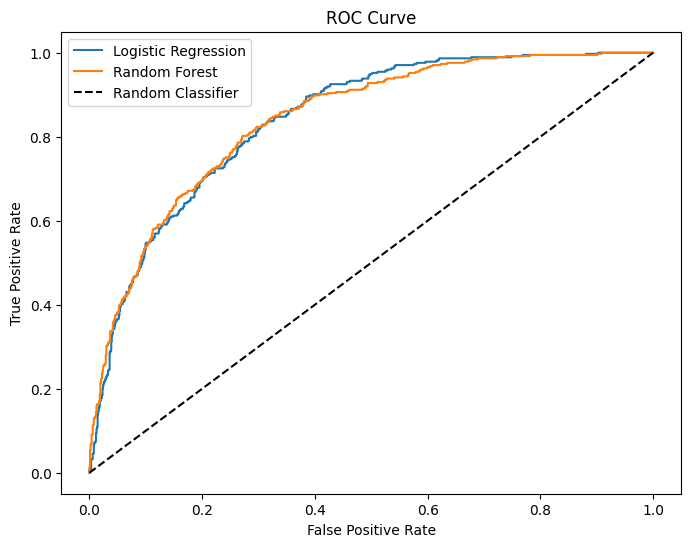

In [60]:
plt.figure(figsize=(8,6))

plt.plot(lr_fpr, lr_tpr,
         label="Logistic Regression")

plt.plot(rf_fpr, rf_tpr,
         label="Random Forest")

plt.plot([0,1],[0,1],'k--',
         label="Random Classifier")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

### ROC-AUC Score

In [63]:
lr_auc = roc_auc_score(y_test, lr_prob)

rf_auc = roc_auc_score(y_test, rf_prob)

print("Logistic Regression AUC :", round(lr_auc,4))

print("Random Forest AUC :", round(rf_auc,4))

Logistic Regression AUC : 0.8409
Random Forest AUC : 0.8409


## ROC Curve and ROC-AUC

Unlike Accuracy, Precision, Recall, and F1 Score, which evaluate the model at a fixed classification threshold, the ROC Curve evaluates model performance across all possible thresholds.

The ROC Curve plots the True Positive Rate (Recall) against the False Positive Rate.

The Area Under the Curve (ROC-AUC) summarizes this curve into a single score. A higher ROC-AUC indicates that the model is better at distinguishing churn customers from non-churn customers.

For customer churn prediction, ROC-AUC is particularly valuable because it measures the model's ranking ability independently of a specific probability threshold.

## ROC Curve Interpretation

Both Logistic Regression and Random Forest achieved a ROC-AUC score of **0.8409**, indicating good discrimination between churn and non-churn customers.

The ROC curves remain well above the diagonal baseline, demonstrating that both models perform significantly better than random guessing.

Since both models have identical ROC-AUC values, they exhibit similar ability to rank customers according to churn risk. However, Logistic Regression achieves higher Recall and F1 Score, making it more suitable for customer churn prediction where identifying churn customers is a higher priority than minimizing false positives.

# **Feature Importance (Random Forest)**

# Feature Importance

Unlike Logistic Regression, Random Forest can estimate how important each feature is while making predictions.

Feature Importance indicates how much each feature contributes to reducing uncertainty (impurity) across all decision trees in the forest.

This analysis helps identify the key business factors influencing customer churn and provides actionable insights for customer retention strategies.

In [70]:
# feature importance scores

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
4,tenure,0.187974
8,TotalCharges,0.165617
7,MonthlyCharges,0.124058
11,InternetService_Fiber optic,0.065477
28,PaymentMethod_Electronic check,0.055743
26,Contract_Two year,0.055243
25,Contract_One year,0.032049
14,OnlineSecurity_Yes,0.031227
20,TechSupport_Yes,0.026095
6,PaperlessBilling,0.024228


### Plotting Top 15 Features

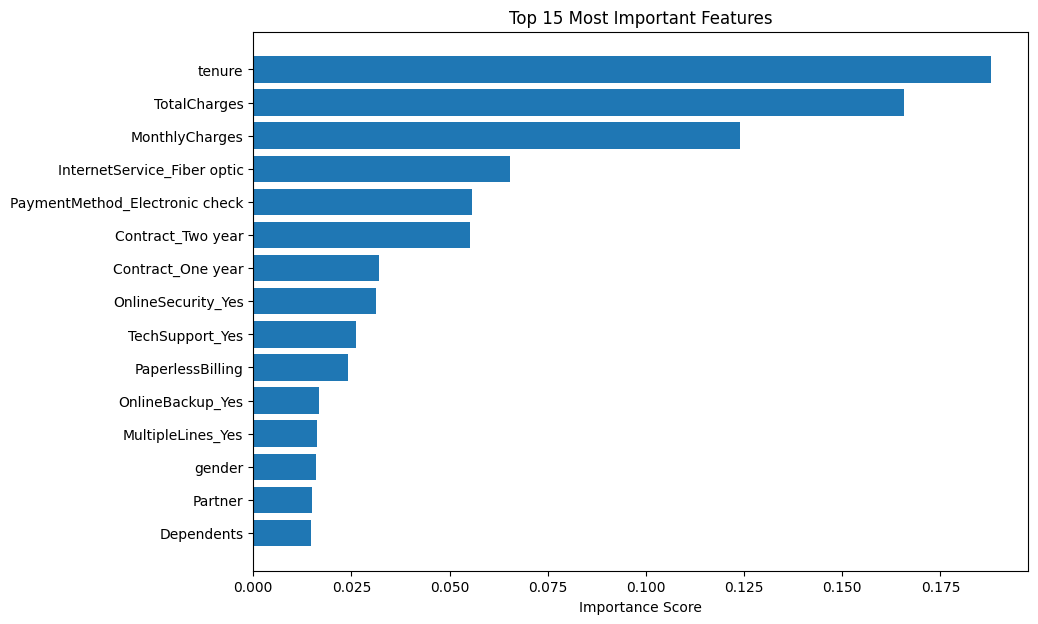

In [73]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10,7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Most Important Features")

plt.xlabel("Importance Score")

plt.gca().invert_yaxis()

plt.show()

In [93]:
feature_importance["Importance (%)"] = (
    feature_importance["Importance"] * 100
).round(2)

feature_importance.head(15)

,Feature,Importance,Importance (%)
4,tenure,0.187974,18.80
8,TotalCharges,0.165617,16.56
7,MonthlyCharges,0.124058,12.41
11,InternetService_Fiber optic,0.065477,6.55
28,PaymentMethod_Electronic check,0.055743,5.57
26,Contract_Two year,0.055243,5.52
25,Contract_One year,0.032049,3.20
14,OnlineSecurity_Yes,0.031227,3.12
20,TechSupport_Yes,0.026095,2.61
6,PaperlessBilling,0.024228,2.42


## Feature Importance Interpretation

The Random Forest model identifies **tenure** as the most influential feature for predicting customer churn, indicating that newer customers are significantly more likely to leave.

Financial variables such as **Total Charges** and **Monthly Charges** also contribute strongly, suggesting that customer spending patterns play an important role in churn behavior.

Service-related features, including **Fiber Optic Internet**, **Online Security**, and **Tech Support**, further influence customer retention. Additionally, customers on **One-Year** and **Two-Year** contracts are less likely to churn than Month-to-Month customers.

Overall, the feature importance analysis reinforces the insights obtained during SQL analysis and exploratory data analysis, demonstrating consistency across multiple stages of the project.

# Final Model Comparison

After training, tuning, and evaluating multiple machine learning models, the final performance of Logistic Regression and Random Forest was compared using multiple evaluation metrics.

Since customer churn prediction is a business-critical problem, model selection is based not only on Accuracy but also on Precision, Recall, F1 Score, and ROC-AUC.

In [97]:
final_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.8020, 0.8034],
    "Precision": [0.6498, 0.6644],
    "Recall": [0.5508, 0.5241],
    "F1 Score": [0.5962, 0.5859],
    "ROC-AUC": [0.8409, 0.8409]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8020,0.6498,0.5508,0.5962,0.8409
1,Random Forest,0.8034,0.6644,0.5241,0.5859,0.8409


In [99]:
final_results.style.highlight_max(
    subset=["Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC-AUC"],
    color="lightgreen"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.802000,0.649800,0.550800,0.596200,0.840900
1,Random Forest,0.803400,0.664400,0.524100,0.585900,0.840900


# Final Model Selection

Although Random Forest achieved slightly higher Accuracy and Precision, Logistic Regression achieved higher Recall and F1 Score while maintaining the same ROC-AUC Score.

For customer churn prediction, Recall is particularly important because failing to identify customers who are likely to churn can result in significant revenue loss.

Therefore, **Logistic Regression** is selected as the final model for deployment because it provides a better balance between identifying churn customers and maintaining overall predictive performance.

# Key Business Insights

The analysis identified several important factors influencing customer churn:

- Customers with shorter tenure are significantly more likely to churn.
- Month-to-Month contract customers have the highest churn risk.
- Customers using Fiber Optic internet service exhibit higher churn rates.
- Higher Monthly Charges are associated with increased churn.
- Customers paying through Electronic Check are more likely to churn.
- Value-added services such as Online Security and Tech Support improve customer retention.
- Long-term contracts substantially reduce churn probability.

# Business Recommendations

Based on the findings of this project, the telecom company should consider the following strategies:

1. Encourage Month-to-Month customers to migrate to One-Year or Two-Year contracts through promotional offers.

2. Improve customer onboarding and engagement during the initial months since newer customers exhibit higher churn rates.

3. Review pricing strategies for customers with high Monthly Charges and provide personalized retention offers where appropriate.

4. Investigate customer satisfaction among Fiber Optic users to identify potential service quality or pricing issues.

5. Promote value-added services such as Online Security and Tech Support to improve customer loyalty.

6. Encourage customers to adopt automatic payment methods instead of Electronic Check through incentives or discounts.

# Project Conclusion

This project successfully developed a machine learning solution for predicting customer churn in a telecom company.

The project followed a complete end-to-end data science workflow, including:

- Data Cleaning
- Exploratory Data Analysis
- SQL Business Analytics
- Feature Engineering
- Data Preprocessing
- Machine Learning Model Development
- Hyperparameter Tuning
- Model Evaluation
- Business Recommendations

Among the evaluated models, Logistic Regression was selected as the final model because it achieved the best balance between Recall and F1 Score while maintaining competitive Accuracy and ROC-AUC performance.

The analysis also identified tenure, contract type, pricing, internet service, and payment method as the most influential factors affecting customer churn.

These findings can help telecom companies proactively identify at-risk customers and implement targeted retention strategies to reduce customer churn and improve long-term profitability.

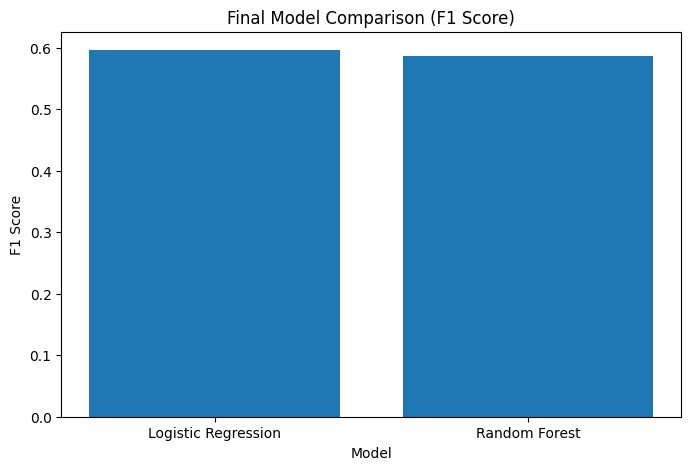

In [107]:
plt.figure(figsize=(8,5))

plt.bar(
    final_results["Model"],
    final_results["F1 Score"]
)

plt.title("Final Model Comparison (F1 Score)")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.show()